# Credit Card Fraud Detection (Colab notebook)
Time-based evaluation of Logistic Regression, Random Forest, Gradient Boosting and **XGBoost**, with class weights and **SMOTE**,
cost-based threshold tuning, and **SHAP** explanations. Dataset: synthetic card transactions (100,000 rows, about 2% fraud).

**How to run:** Runtime > Run all. When asked, upload `credit_card_fraud_detection_2026.csv`.
The script `src/fraud_pipeline.py` in the repository runs the scikit-learn part without any extra installs; this notebook adds XGBoost, SMOTE and SHAP.

In [10]:
!pip -q install imbalanced-learn xgboost shap

In [11]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap, warnings
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score
from imblearn.pipeline import Pipeline            # imblearn Pipeline so SMOTE touches training data only
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
warnings.filterwarnings("ignore"); SEED = 42; REVIEW_COST = 5.0

## 1. Load the data

In [12]:
from google.colab import files
up = files.upload()                                   # choose credit_card_fraud_detection_2026.csv
df = pd.read_csv(list(up)[0], parse_dates=["transaction_datetime"]).sort_values("transaction_datetime").reset_index(drop=True)
df["browser"] = df["browser"].fillna("None")          # empty for in-store and ATM transactions
print(df.shape, f"fraud rate {df.is_fraud.mean():.2%}")
df.is_fraud.value_counts()

Saving credit_card_fraud_detection_2026.csv to credit_card_fraud_detection_2026 (1).csv
(100000, 43) fraud rate 2.05%


,count
is_fraud,
0,97945
1,2055


## 2. Leakage check and time-based split
* `fraud_type` and `fraud_amount_lost` are only known **after** fraud is confirmed, so they are excluded from the features.
* ID columns are excluded because they would let a model memorise customers.
* The split follows time: first 60% train, next 20% validation (threshold choice), last 20% test. A random split would let the model learn from the future.

In [13]:
IDS = ["transaction_id","customer_id","card_id","merchant_id","transaction_datetime"]
LEAK = ["fraud_type","fraud_amount_lost"]
feats = [c for c in df.columns if c not in IDS + LEAK + ["is_fraud"]]
n = len(df); tr, va, te = df.iloc[:int(.6*n)], df.iloc[int(.6*n):int(.8*n)], df.iloc[int(.8*n):]
for name, p in [("train",tr),("validation",va),("test",te)]:
    print(f"{name:10s} {p.transaction_datetime.min():%Y-%m-%d} to {p.transaction_datetime.max():%Y-%m-%d}  n={len(p)}  fraud={p.is_fraud.mean():.2%}")
num = df[feats].select_dtypes("number").columns.tolist(); cat = [c for c in feats if c not in num]
def prep(): return ColumnTransformer([("num",StandardScaler(),num),("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),cat)])

train      2026-01-01 to 2026-08-08  n=60000  fraud=2.04%
validation 2026-08-08 to 2026-10-20  n=20000  fraud=2.08%
test       2026-10-20 to 2026-12-31  n=20000  fraud=2.08%


## 3. Compare models: no handling, class weights, SMOTE
Accuracy is not used: a model that never flags anything is 98% accurate. We report **PR-AUC** (area under the precision-recall curve; chance level is the fraud rate, about 0.02), ROC-AUC, and precision and recall at threshold 0.5.

In [14]:
spw = (tr.is_fraud==0).sum() / (tr.is_fraud==1).sum()
def models(mode):
    w = mode == "class weights"
    return {
      "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced" if w else None),
      "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED,
                                              class_weight="balanced_subsample" if w else None),
      "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced" if w else None, random_state=SEED),
      "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=.05, subsample=.8, eval_metric="aucpr",
                               scale_pos_weight=spw if w else 1, n_jobs=-1, random_state=SEED),
    }
rows, fitted, vs, ts = [], {}, {}, {}
for mode in ["none", "class weights", "SMOTE"]:
    for name, clf in models(mode).items():
        steps = [("prep", prep())] + ([("smote", SMOTE(sampling_strategy=0.2, random_state=SEED))] if mode=="SMOTE" else []) + [("clf", clf)]
        pipe = Pipeline(steps).fit(tr[feats], tr.is_fraud)
        pv, pt = pipe.predict_proba(va[feats])[:,1], pipe.predict_proba(te[feats])[:,1]
        fitted[(name,mode)], vs[(name,mode)], ts[(name,mode)] = pipe, pv, pt
        pred = (pt >= .5).astype(int)
        rows.append(dict(model=name, imbalance=mode, roc_auc=roc_auc_score(te.is_fraud,pt), pr_auc=average_precision_score(te.is_fraud,pt),
                         precision_at_0_5=precision_score(te.is_fraud,pred,zero_division=0), recall_at_0_5=recall_score(te.is_fraud,pred)))
res = pd.DataFrame(rows).round(3); res

,model,imbalance,roc_auc,pr_auc,precision_at_0_5,recall_at_0_5
0,Logistic Regression,none,0.836,0.127,0.556,0.012
1,Random Forest,none,0.835,0.144,0.000,0.000
2,Gradient Boosting,none,0.838,0.137,0.419,0.043
3,XGBoost,none,0.845,0.160,0.444,0.019
4,Logistic Regression,class weights,0.834,0.122,0.059,0.748
5,Random Forest,class weights,0.836,0.135,0.344,0.026
6,Gradient Boosting,class weights,0.841,0.151,0.074,0.705
7,XGBoost,class weights,0.836,0.145,0.079,0.638
8,Logistic Regression,SMOTE,0.826,0.120,0.159,0.314
9,Random Forest,SMOTE,0.832,0.124,0.000,0.000


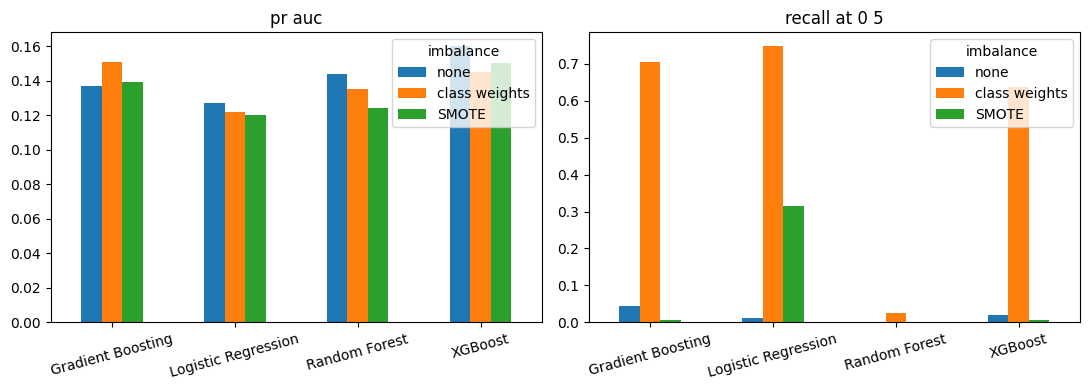

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col in zip(ax, ["pr_auc", "recall_at_0_5"]):
    res.pivot(index="model", columns="imbalance", values=col)[["none","class weights","SMOTE"]].plot.bar(ax=a, rot=15)
    a.set_title(col.replace("_"," ")); a.set_xlabel("")
plt.tight_layout(); plt.show()

## 4. Select the model on validation, then tune the threshold by cost
The model is chosen on **validation** PR-AUC, never on test. Assumed costs: a missed fraud loses `fraud_amount_lost`; reviewing any flagged transaction costs 5 USD (an assumption you can change).

selected: ('XGBoost', 'SMOTE') 0.1556
threshold 0.055
test cost with no model: 67137
test cost at 0.5       : 66500
test cost at tuned thr : 33261


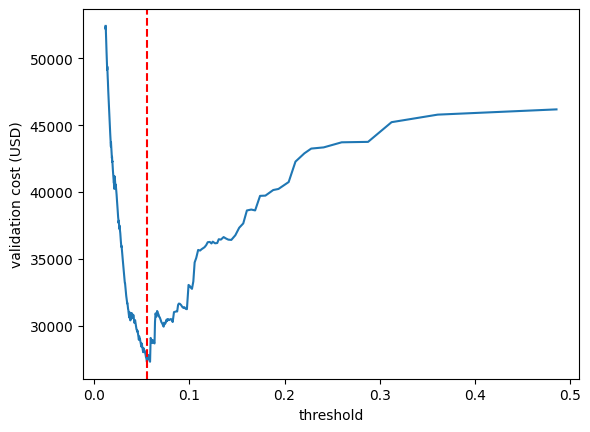

In [16]:
val_pr = {k: average_precision_score(va.is_fraud, v) for k, v in vs.items()}
best = max(val_pr, key=val_pr.get); print("selected:", best, round(val_pr[best], 4))
def cost(y, loss, p, thr):
    f = p >= thr; return float(loss[(~f) & (y==1)].sum() + REVIEW_COST * f.sum())
grid = np.unique(np.quantile(vs[best], np.linspace(.5, .9995, 400)))
costs = [cost(va.is_fraud.values, va.fraud_amount_lost.values, vs[best], t) for t in grid]
thr = grid[int(np.argmin(costs))]
y, loss, pt = te.is_fraud.values, te.fraud_amount_lost.values, ts[best]
print(f"threshold {thr:.3f}")
print("test cost with no model:", round(loss[y==1].sum()))
print("test cost at 0.5       :", round(cost(y, loss, pt, .5)))
print("test cost at tuned thr :", round(cost(y, loss, pt, thr)))
plt.plot(grid, costs); plt.axvline(thr, color="r", ls="--"); plt.xlabel("threshold"); plt.ylabel("validation cost (USD)"); plt.show()

## 5. Which fraud types are caught?

In [17]:
t = te.assign(caught=(pt >= thr).astype(int))
t[t.is_fraud==1].groupby("fraud_type").agg(n=("caught","size"), recall=("caught","mean"), avg_loss=("fraud_amount_lost","mean")).round(3)

,n,recall,avg_loss
fraud_type,,,
Account-Takeover,87,0.517,159.203
Card-Not-Present,222,0.626,160.546
Card-Present,47,0.340,156.128
Synthetic-Identity,61,0.656,168.964


## 6. SHAP explanation of the selected model
SHAP shows how much each feature pushed a prediction up or down. Computed on a 2,000-row test sample of the transformed features.

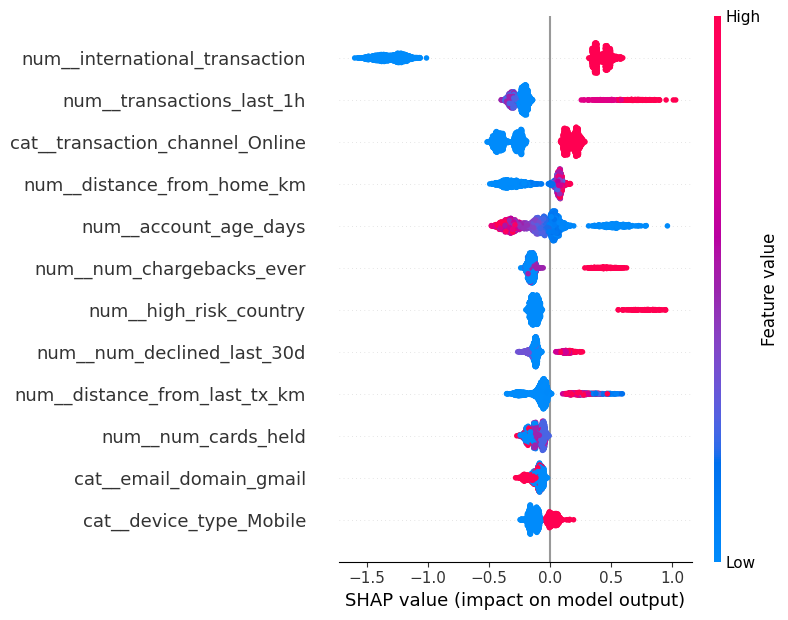

In [18]:
pipe = fitted[best]; clf = pipe.named_steps["clf"]; Xt = pipe.named_steps["prep"].transform(te[feats].iloc[:2000])
names = pipe.named_steps["prep"].get_feature_names_out()
try:
    sv = shap.TreeExplainer(clf).shap_values(Xt)
except Exception:                                   # linear model or tree type not supported
    sv = shap.LinearExplainer(clf, pipe.named_steps["prep"].transform(tr[feats].iloc[:2000])).shap_values(Xt)
if isinstance(sv, list): sv = sv[1]
shap.summary_plot(sv, Xt, feature_names=names, max_display=12)

## 7. Conclusions
Fill in after running: which model and imbalance method won on validation, how PR-AUC compares with the 0.02 chance level, whether threshold tuning on validation also helped on test, and which features SHAP ranks highest.
The data is synthetic, so the results show that the pipeline works, not that it would catch real fraud.